# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Evelin Alim Natadjaja
- **Email:** evelinalim20@gmail.com
- **ID Dicoding:** DS197B6X0524

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren total nilai penjualan (revenue) bulanan pada setiap kategori produk, dan kategori produk mana yang memberikan kontribusi revenue terbesar selama periode Januari 2017 hingga Agustus 2018 pada platform E-Commerce Brazil?

- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata skor ulasan pelanggan antara pesanan yang dikirim tepat waktu dan pesanan yang terlambat diterima, serta bagaimana tingkat keterlambatan pengiriman pada platform E-Commerce Brazil selama periode Januari 2017 hingga Agustus 2018?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Konfigurasi tampilan dataframe
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries berhasil di-import!")


Libraries berhasil di-import!


## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
# Memuat seluruh dataset
customers_df = pd.read_csv("data/customers_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
category_translation_df = pd.read_csv("data/product_category_name_translation.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
sellers_df = pd.read_csv("data/sellers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")

print("Seluruh dataset berhasil dimuat!")


Seluruh dataset berhasil dimuat!


In [3]:
# Mengumpulkan seluruh DataFrame
dataframes = {
    "Customers": customers_df,
    "Orders": orders_df,
    "Order Items": order_items_df,
    "Products": products_df,
    "Category Translation": category_translation_df,
    "Order Reviews": order_reviews_df,
    "Order Payments": order_payments_df,
    "Sellers": sellers_df,
    "Geolocation": geolocation_df
}

# Menampilkan jumlah baris dan kolom
for name, df in dataframes.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Customers: 99,441 rows, 5 columns
Orders: 99,441 rows, 8 columns
Order Items: 112,650 rows, 7 columns
Products: 32,951 rows, 9 columns
Category Translation: 71 rows, 2 columns
Order Reviews: 99,224 rows, 7 columns
Order Payments: 103,886 rows, 5 columns
Sellers: 3,095 rows, 4 columns
Geolocation: 1,000,163 rows, 5 columns


In [4]:
# Melihat struktur setiap dataset
for name, df in dataframes.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print(f"{'='*50}")

    print(df.info())
    display(df.head(3))



DATASET: Customers
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB
None


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



DATASET: Orders
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



DATASET: Order Items
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
None


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


... (8 outputs left out)


DATASET: Sellers
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB
None


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ



DATASET: Geolocation
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB
None


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


### Insight – Gathering Data

- Berhasil memuat seluruh 9 dataset E-Commerce Public Dataset tanpa kendala.
- Dataset memiliki jumlah data yang bervariasi, mulai dari 71 baris pada Category Translation hingga 1.000.163 baris pada Geolocation.
- Dataset `Orders` dan `Customers` masing-masing memiliki 99.441 baris, sedangkan `Order Items` memiliki 112.650 baris.
- Setiap dataset memiliki informasi berbeda yang saling melengkapi, seperti pelanggan, pesanan, produk, pembayaran, ulasan, penjual, dan lokasi geografis.
- Dataset `Orders` dan `Order Items` menjadi sumber utama untuk analisis penjualan dan pengiriman.
- Dataset `Customers` akan membantu mengidentifikasi pelanggan unik dalam analisis RFM.

### Assessing Data

#### Identifying Missing Values

In [5]:
for name, df in dataframes.items():
    print(f"\n===== {name} =====")

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print("Tidak ditemukan missing values.")
    else:
        missing_summary = pd.DataFrame({
            "Jumlah Missing": missing,
            "Persentase (%)": (missing / len(df) * 100).round(2)
        })

        display(missing_summary)



===== Customers =====
Tidak ditemukan missing values.

===== Orders =====


,Jumlah Missing,Persentase (%)
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



===== Order Items =====
Tidak ditemukan missing values.

===== Products =====


,Jumlah Missing,Persentase (%)
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



===== Category Translation =====
Tidak ditemukan missing values.

===== Order Reviews =====


,Jumlah Missing,Persentase (%)
review_comment_title,87656,88.34
review_comment_message,58247,58.70



===== Order Payments =====
Tidak ditemukan missing values.

===== Sellers =====
Tidak ditemukan missing values.

===== Geolocation =====
Tidak ditemukan missing values.


#### Identifying Duplicate Value

In [6]:
for name, df in dataframes.items():
    duplicate_count = df.duplicated().sum()

    print(f"{name}: {duplicate_count:,} baris duplikat")


Customers: 0 baris duplikat
Orders: 0 baris duplikat
Order Items: 0 baris duplikat
Products: 0 baris duplikat
Category Translation: 0 baris duplikat
Order Reviews: 0 baris duplikat
Order Payments: 0 baris duplikat
Sellers: 0 baris duplikat
Geolocation: 261,831 baris duplikat


#### Identifying Data Types

In [7]:

for name, df in dataframes.items():
    print(f"\n===== {name} =====")
    print(df.dtypes)



===== Customers =====
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

===== Orders =====
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

===== Order Items =====
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

===== Products =====
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            flo

#### Identifying Data Distribution

In [8]:
print("===== Distribusi Status Pesanan =====")
display(orders_df["order_status"].value_counts(dropna=False))

print("\n===== Distribusi Skor Ulasan =====")
display(order_reviews_df["review_score"].value_counts(dropna=False).sort_index())


===== Distribusi Status Pesanan =====


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


===== Distribusi Skor Ulasan =====


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [9]:
print("===== Statistik Harga dan Ongkos Kirim =====")
display(
    order_items_df[["price", "freight_value"]].describe()
)


===== Statistik Harga dan Ongkos Kirim =====


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


In [10]:
print("Jumlah harga negatif:",
      (order_items_df["price"] < 0).sum())

print("Jumlah ongkos kirim negatif:",
      (order_items_df["freight_value"] < 0).sum())

print("Jumlah skor ulasan di luar rentang 1–5:",
      (~order_reviews_df["review_score"].between(1, 5)).sum())


Jumlah harga negatif: 0
Jumlah ongkos kirim negatif: 0
Jumlah skor ulasan di luar rentang 1–5: 0


**Steps to Take:**
- Missing values Orders: Periksa status pesanan sebelum menentukan penanganan tanggal kosong. Gunakan hanya tanggal valid untuk analisis pengiriman.

- Missing values Products: Isi product_category_name yang kosong dengan label Unknown. Biarkan atribut lain yang tidak diperlukan dalam analisis.

- Missing values Order Reviews: Pertahankan nilai kosong pada kolom komentar karena komentar bersifat opsional.

- Duplicate Geolocation: Hapus baris yang benar-benar identik dan pertahankan satu salinannya.

- Tipe data tanggal: Konversi kolom tanggal bertipe object menjadi datetime.

- Validitas data: Pertahankan harga, ongkos kirim, dan skor ulasan karena tidak ditemukan nilai yang tidak valid. Filter status pesanan sesuai kebutuhan analisis.

**Insight:** (Opsional)
- Ditemukan missing values pada dataset Orders, Products, dan Order Reviews.

- Dataset Geolocation memiliki 261.831 baris duplikat, sedangkan delapan dataset lainnya tidak memiliki duplikasi.

- Beberapa kolom tanggal masih bertipe object sehingga perlu dikonversi menjadi datetime.

- Tidak ditemukan harga negatif, ongkos kirim negatif, maupun skor ulasan di luar rentang 1–5.

- Secara keseluruhan, dataset dapat digunakan untuk analisis setelah permasalahan kualitas data ditangani pada tahap Cleaning Data.

### Cleaning Data

In [11]:
# Membuat salinan DataFrame untuk proses cleaning
customers_clean = customers_df.copy()
orders_clean = orders_df.copy()
order_items_clean = order_items_df.copy()
products_clean = products_df.copy()
category_translation_clean = category_translation_df.copy()
order_reviews_clean = order_reviews_df.copy()
order_payments_clean = order_payments_df.copy()
sellers_clean = sellers_df.copy()
geolocation_clean = geolocation_df.copy()

print("Salinan DataFrame berhasil dibuat!")

Salinan DataFrame berhasil dibuat!


#### Fixing Missing Values

In [12]:
# Membuat salinan dataset Orders
orders_clean = orders_df.copy()

# Mengonversi kolom tanggal menjadi datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

# Memeriksa missing values setelah konversi
display(orders_clean.isna().sum().to_frame("Jumlah Missing"))

,Jumlah Missing
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


**Insight:**
- Kolom tanggal pembelian (order_purchase_timestamp) dan estimasi pengiriman (order_estimated_delivery_date) tidak memiliki missing values.

- Ditemukan 160 missing values pada order_approved_at.

- Ditemukan 1.783 missing values pada order_delivered_carrier_date.

- Ditemukan 2.965 missing values pada order_delivered_customer_date.

- Missing values pada kolom tanggal pengiriman dipertahankan karena dapat menunjukkan pesanan yang belum selesai diproses atau dikirim.

- Seluruh kolom tanggal berhasil dikonversi menjadi tipe data datetime tanpa menambah missing values baru.

In [13]:
# Membuat salinan dataset Products
products_clean = products_df.copy()

# Mengisi kategori produk yang kosong
products_clean["product_category_name"] = (
    products_clean["product_category_name"].fillna("Unknown")
)

# Memeriksa missing values setelah cleaning
display(products_clean.isna().sum().to_frame("Jumlah Missing"))

,Jumlah Missing
product_id,0
product_category_name,0
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


**Insight:**
- Missing values pada product_category_name berhasil ditangani dengan mengisi label Unknown, sehingga tidak ada lagi kategori produk yang kosong.
- Atribut product_name_lenght, product_description_lenght, dan product_photos_qty masih memiliki masing-masing 610 missing values.
- Atribut berat dan dimensi produk masing-masing masih memiliki 2 missing values.
- Missing values pada atribut selain kategori dipertahankan karena tidak diperlukan untuk menjawab pertanyaan bisnis utama.

In [14]:
# Membuat salinan dataset Order Reviews
order_reviews_clean = order_reviews_df.copy()

# Mengonversi kolom tanggal menjadi datetime
review_date_columns = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in review_date_columns:
    order_reviews_clean[col] = pd.to_datetime(
        order_reviews_clean[col],
        errors="coerce"
    )

# Memeriksa missing values
display(order_reviews_clean.isna().sum().to_frame("Jumlah Missing"))

,Jumlah Missing
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


**Insight:**
- Kolom review_comment_title memiliki 87.656 missing values, sedangkan review_comment_message memiliki 58.247 missing values.

- Missing values pada kedua kolom komentar dipertahankan karena komentar bersifat opsional dan tidak digunakan dalam pertanyaan bisnis utama.

- Kolom tanggal review_creation_date dan review_answer_timestamp berhasil dikonversi ke format datetime tanpa missing values.

- Kolom penting untuk analisis, yaitu order_id dan review_score, tidak memiliki missing values.

In [15]:
# Membuat salinan dataset Geolocation
geolocation_clean = geolocation_df.copy()

# Menghapus baris duplikat
geolocation_clean = geolocation_clean.drop_duplicates()

# Memeriksa jumlah duplikat setelah cleaning
print(
    "Jumlah duplikat setelah cleaning:",
    geolocation_clean.duplicated().sum()
)

print("Jumlah baris sebelum cleaning:", len(geolocation_df))
print("Jumlah baris setelah cleaning:", len(geolocation_clean))

Jumlah duplikat setelah cleaning: 0
Jumlah baris sebelum cleaning: 1000163
Jumlah baris setelah cleaning: 738332


**Insight**
- Dataset Geolocation awalnya memiliki 1.000.163 baris.
- Sebanyak 261.831 baris duplikat berhasil dihapus.
- Setelah cleaning, jumlah data menjadi 738.332 baris.
- Tidak ditemukan lagi duplikasi berdasarkan seluruh kolom setelah proses cleaning.
- Penghapusan hanya dilakukan pada baris yang identik sepenuhnya, sehingga data dengan kode pos sama tetapi koordinat atau informasi lainnya berbeda tetap dipertahankan.

In [16]:
# Membuat salinan dataset Order Items
order_items_clean = order_items_df.copy()

# Mengonversi kolom tanggal
order_items_clean["shipping_limit_date"] = pd.to_datetime(
    order_items_clean["shipping_limit_date"],
    errors="coerce"
)

# Memeriksa tipe data setelah konversi
print(order_items_clean.dtypes)

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object


**Insight**
- Kolom shipping_limit_date berhasil dikonversi dari tipe object menjadi datetime64.
- Kolom lainnya memiliki tipe data yang sesuai, yaitu object untuk identitas pesanan dan produk, int64 untuk nomor item, serta float64 untuk harga dan ongkos kirim.
- Dataset Order Items kini memiliki format tanggal yang siap digunakan untuk analisis berbasis waktu.

In [17]:
# Mengumpulkan dataset hasil cleaning
cleaned_dataframes = {
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Products": products_clean,
    "Order Reviews": order_reviews_clean,
    "Geolocation": geolocation_clean
}

# Memeriksa duplikasi dan missing values
for name, df in cleaned_dataframes.items():
    print(f"\n===== {name} =====")
    print("Jumlah baris:", len(df))
    print("Jumlah duplikat:", df.duplicated().sum())
    print("Jumlah missing values:", df.isna().sum().sum())


===== Orders =====
Jumlah baris: 99441
Jumlah duplikat: 0
Jumlah missing values: 4908

===== Order Items =====
Jumlah baris: 112650
Jumlah duplikat: 0
Jumlah missing values: 0

===== Products =====
Jumlah baris: 32951
Jumlah duplikat: 0
Jumlah missing values: 1838

===== Order Reviews =====
Jumlah baris: 99224
Jumlah duplikat: 0
Jumlah missing values: 145903

===== Geolocation =====
Jumlah baris: 738332
Jumlah duplikat: 0
Jumlah missing values: 0


**Insight:**
- Orders: Tidak ditemukan duplikasi. Terdapat 4.908 missing values yang sebagian besar berkaitan dengan kolom tanggal proses pengiriman dan penyelesaian pesanan.
- Order Items: Tidak ditemukan duplikasi maupun missing values. Dataset siap digunakan untuk analisis penjualan dan pengiriman.
- Products: Tidak ditemukan duplikasi. Masih terdapat 1.838 missing values pada atribut produk yang tidak digunakan dalam pertanyaan bisnis utama.
- Order Reviews: Tidak ditemukan duplikasi. Missing values masih terdapat pada kolom komentar yang bersifat opsional.
- Geolocation: Sebanyak 261.831 baris duplikat berhasil dihapus dan tidak ditemukan lagi missing values maupun duplikasi.

## Exploratory Data Analysis (EDA)

### Explore rentang waktu dan status pesanan

In [18]:
# Melihat rentang waktu transaksi
print("Rentang waktu transaksi:")
print("Tanggal paling awal:", orders_clean["order_purchase_timestamp"].min())
print("Tanggal paling akhir:", orders_clean["order_purchase_timestamp"].max())

# Melihat distribusi status pesanan
print("\nDistribusi Status Pesanan:")
display(
    orders_clean["order_status"]
    .value_counts()
    .to_frame("Jumlah Pesanan")
)

# Melihat jumlah pesanan per bulan
monthly_orders = (
    orders_clean
    .set_index("order_purchase_timestamp")
    .resample("ME")
    .size()
    .to_frame("Jumlah Pesanan")
)

display(monthly_orders.head(10))

Rentang waktu transaksi:
Tanggal paling awal: 2016-09-04 21:15:19
Tanggal paling akhir: 2018-10-17 17:30:18

Distribusi Status Pesanan:


,Jumlah Pesanan
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,Jumlah Pesanan
order_purchase_timestamp,
2016-09-30,4
2016-10-31,324
2016-11-30,0
2016-12-31,1
2017-01-31,800
2017-02-28,1780
2017-03-31,2682
2017-04-30,2404
2017-05-31,3700


**Insight:**
- Rentang waktu transaksi berlangsung dari 4 September 2016 hingga 17 Oktober 2018.

- Status pesanan didominasi oleh delivered sebanyak 96.478 pesanan, sehingga mayoritas transaksi berhasil sampai kepada pelanggan.

- Terdapat 1.107 pesanan berstatus shipped, 625 canceled, dan 609 unavailable. Status lainnya memiliki jumlah yang relatif kecil.

- Jumlah pesanan mulai meningkat pada awal 2017. Januari mencatat 800 pesanan, Februari 1.780 pesanan, dan Maret 2.682 pesanan.

- Terdapat bulan dengan jumlah transaksi sangat sedikit, seperti November 2016 (0 pesanan) dan Desember 2016 (1 pesanan). Ini menunjukkan aktivitas pada periode awal dataset belum konsisten.

### Eksplorasi kategori produk

In [19]:
# Menggabungkan data Order Items dengan Orders
product_analysis = (
    order_items_clean
    .merge(
        orders_clean[[
            "order_id",
            "order_status",
            "order_purchase_timestamp"
        ]],
        on="order_id",
        how="inner"
    )
)

# Memfilter pesanan delivered pada periode Januari 2017–Agustus 2018
product_analysis = product_analysis[
    (product_analysis["order_status"] == "delivered") &
    (product_analysis["order_purchase_timestamp"] >= "2017-01-01") &
    (product_analysis["order_purchase_timestamp"] < "2018-09-01")
]

# Menggabungkan data produk dan terjemahan kategori
product_analysis = (
    product_analysis
    .merge(
        products_clean[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .merge(
        category_translation_df,
        on="product_category_name",
        how="left"
    )
)

# Menangani kategori yang belum memiliki terjemahan
product_analysis["product_category_name_english"] = (
    product_analysis["product_category_name_english"]
    .fillna("Unknown")
)

# Menghitung jumlah item dan revenue per kategori
category_summary = (
    product_analysis
    .groupby("product_category_name_english")
    .agg(
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(category_summary.head(10))

,total_items,total_revenue
product_category_name_english,,
health_beauty,9422,"1,229,557.50"
watches_gifts,5855,"1,163,465.91"
bed_bath_table,10945,"1,022,955.77"
sports_leisure,8414,"952,840.40"
computers_accessories,7632,"888,055.59"
furniture_decor,8095,"706,237.17"
housewares,6783,"614,341.62"
cool_stuff,3711,"609,158.00"
auto,4132,"577,838.39"


**Insight:**
- Kategori health_beauty memiliki total revenue tertinggi, yaitu 1.229.557,50, dengan 9.422 item terjual.
- Kategori watches_gifts menempati posisi kedua dengan revenue 1.163.465,91 dari 5.855 item.
- Kategori bed_bath_table mencatat jumlah item terjual terbanyak, yaitu 10.945 item, dengan revenue sebesar 1.022.955,77.
- Kategori sports_leisure dan computers_accessories juga memberikan kontribusi revenue yang besar, masing-masing sebesar 952.840,40 dan 888.055,59.
- Hasil ini menunjukkan bahwa kategori dengan jumlah item terjual terbanyak belum tentu menjadi kategori dengan revenue tertinggi.

### Explore Pengiriman dan Skor Ulasan

In [20]:
# Mengambil pesanan delivered pada periode analisis
delivery_analysis = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_clean["order_purchase_timestamp"] < "2018-09-01")
].copy()

# Memastikan kolom tanggal pengiriman tersedia
delivery_analysis = delivery_analysis.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Menentukan status ketepatan waktu pengiriman
delivery_analysis["delivery_status"] = np.where(
    delivery_analysis["order_delivered_customer_date"] >
    delivery_analysis["order_estimated_delivery_date"],
    "Late",
    "On Time"
)

# Menghitung jumlah dan persentase pesanan berdasarkan status pengiriman
delivery_summary = (
    delivery_analysis["delivery_status"]
    .value_counts()
    .to_frame("Jumlah Pesanan")
)

delivery_summary["Persentase (%)"] = (
    delivery_summary["Jumlah Pesanan"] /
    delivery_summary["Jumlah Pesanan"].sum() * 100
).round(2)

display(delivery_summary)

,Jumlah Pesanan,Persentase (%)
delivery_status,,
On Time,88381,91.87
Late,7822,8.13


**Insight:**
- Sebanyak 88.381 pesanan (91,87%) berhasil diterima pelanggan tepat waktu.
- Sebanyak 7.822 pesanan (8,13%) mengalami keterlambatan pengiriman.
- Mayoritas pesanan berhasil dikirim sesuai estimasi waktu yang diberikan kepada pelanggan.
- Meskipun persentase keterlambatan relatif kecil, jumlah 7.822 pesanan tetap perlu diperhatikan karena keterlambatan dapat berkaitan dengan pengalaman pelanggan.

### Explore Perbandingan Skor Ulasan

In [21]:
# Menghitung rata-rata skor ulasan untuk setiap pesanan
reviews_per_order = (
    order_reviews_clean
    .groupby("order_id")
    .agg(
        review_score=("review_score", "mean")
    )
    .reset_index()
)

# Menggabungkan data pengiriman dengan skor ulasan
delivery_reviews = delivery_analysis.merge(
    reviews_per_order,
    on="order_id",
    how="inner"
)

# Menghitung rata-rata skor ulasan berdasarkan status pengiriman
review_summary = (
    delivery_reviews
    .groupby("delivery_status")
    .agg(
        jumlah_pesanan=("order_id", "nunique"),
        rata_rata_review=("review_score", "mean")
    )
    .round(2)
)

display(review_summary)

# Menghitung selisih rata-rata skor ulasan
score_difference = (
    review_summary.loc["On Time", "rata_rata_review"] -
    review_summary.loc["Late", "rata_rata_review"]
)

print(
    "Selisih rata-rata skor ulasan (On Time - Late):",
    round(score_difference, 2)
)

,jumlah_pesanan,rata_rata_review
delivery_status,,
Late,7658,2.57
On Time,87902,4.30


Selisih rata-rata skor ulasan (On Time - Late): 1.73


**Insight:**
- Periode transaksi yang digunakan adalah Januari 2017 hingga Agustus 2018 karena periode tersebut memiliki aktivitas transaksi yang lebih representatif.
- Kategori health_beauty menghasilkan revenue tertinggi sebesar 1.229.557,50, sedangkan bed_bath_table memiliki jumlah item terjual terbanyak sebanyak 10.945 item.
- Sebanyak 91,87% pesanan berhasil diterima tepat waktu, sementara 8,13% mengalami keterlambatan.
- Rata-rata skor ulasan pesanan tepat waktu adalah 4,30, sedangkan pesanan terlambat memiliki rata-rata skor 2,57.
- Terdapat selisih rata-rata skor ulasan sebesar 1,73 poin antara kedua kelompok. Hal ini menunjukkan adanya hubungan antara ketepatan waktu pengiriman dan skor ulasan pelanggan, tetapi belum membuktikan hubungan sebab-akibat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren total nilai penjualan (revenue) bulanan pada setiap kategori produk, dan kategori produk mana yang memberikan kontribusi revenue terbesar selama periode Januari 2017 hingga Agustus 2018?

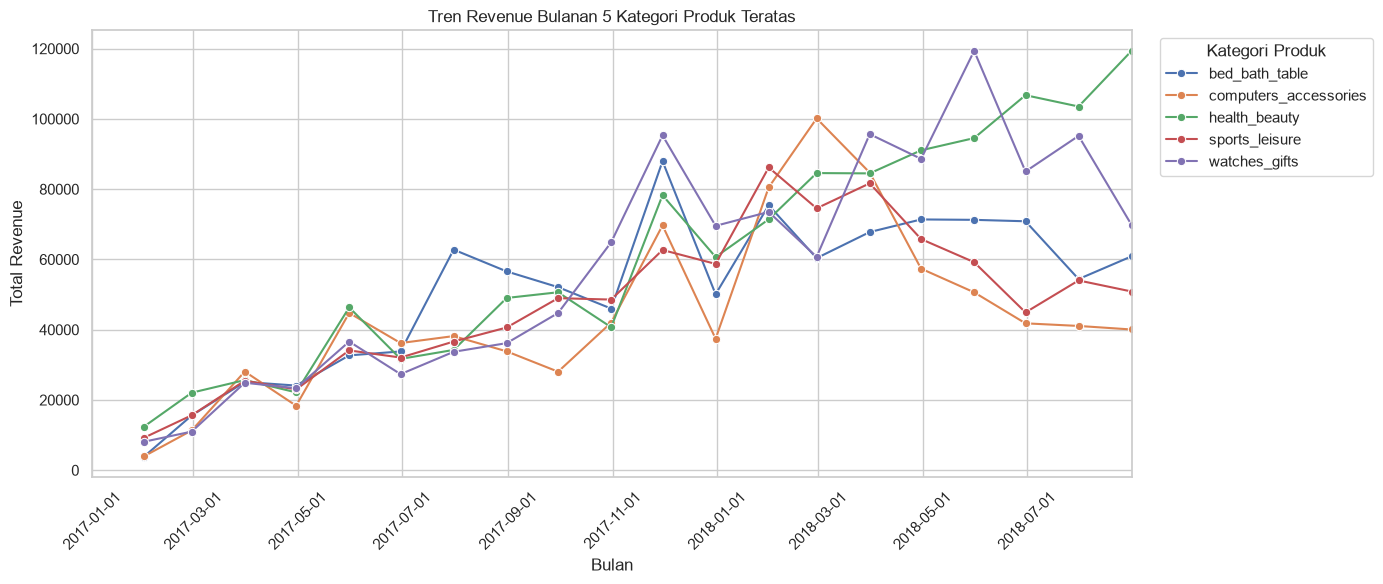

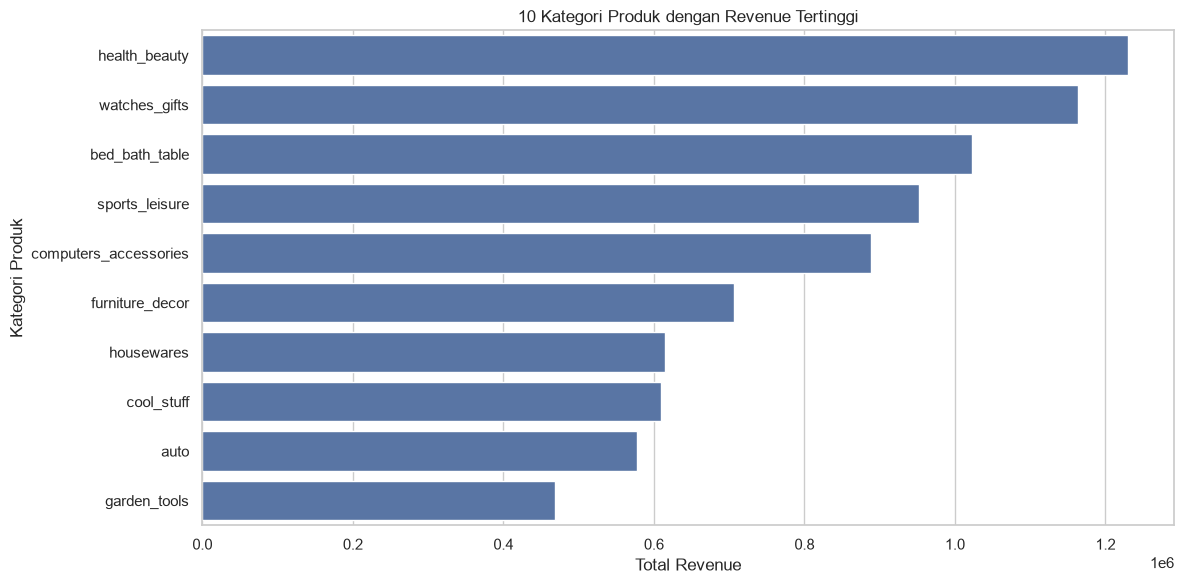

In [22]:
# Mengambil 5 kategori dengan revenue tertinggi
top_categories = (
    category_summary
    .head(5)
    .index
    .tolist()
)

# Menghitung revenue bulanan untuk setiap kategori
monthly_category_revenue = (
    product_analysis[
        product_analysis["product_category_name_english"].isin(top_categories)
    ]
    .set_index("order_purchase_timestamp")
    .groupby("product_category_name_english")["price"]
    .resample("ME")
    .sum()
    .reset_index()
)

# Visualisasi tren revenue bulanan
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_category_revenue,
    x="order_purchase_timestamp",
    y="price",
    hue="product_category_name_english",
    marker="o"
)

plt.title("Tren Revenue Bulanan 5 Kategori Produk Teratas")
plt.xlabel("Bulan")
plt.ylabel("Total Revenue")

# Mengatur format label sumbu X
plt.xlim(
    pd.Timestamp("2017-01-01"),
    pd.Timestamp("2018-08-31")
)

plt.xticks(
    pd.date_range("2017-01-01", "2018-08-01", freq="2MS"),
    rotation=45
)

plt.legend(title="Kategori Produk", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# Visualisasi 10 kategori dengan revenue tertinggi
top_10_categories = category_summary.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_categories,
    x="total_revenue",
    y="product_category_name_english"
)

plt.title("10 Kategori Produk dengan Revenue Tertinggi")
plt.xlabel("Total Revenue")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

**Insight:**
- Kategori health_beauty menghasilkan revenue tertinggi selama periode Januari 2017–Agustus 2018, yaitu sekitar 1,23 juta.
- Kategori watches_gifts berada di posisi kedua dengan revenue sekitar 1,16 juta.
- Kategori bed_bath_table memiliki jumlah item terjual terbanyak, tetapi revenue-nya berada di posisi ketiga.
- Grafik tren bulanan menunjukkan bahwa revenue beberapa kategori mengalami fluktuasi dari bulan ke bulan.
- Kategori health_beauty menunjukkan tren peningkatan yang cukup kuat pada pertengahan hingga akhir 2018 dan mencapai revenue bulanan tertinggi sekitar September 2018.
- Kategori watches_gifts juga mengalami beberapa lonjakan revenue, tetapi pergerakannya lebih fluktuatif.

### Pertanyaan 2: Seberapa besar perbedaan rata-rata skor ulasan pelanggan antara pesanan yang dikirim tepat waktu dan pesanan yang terlambat diterima, serta bagaimana tingkat keterlambatan pengiriman?

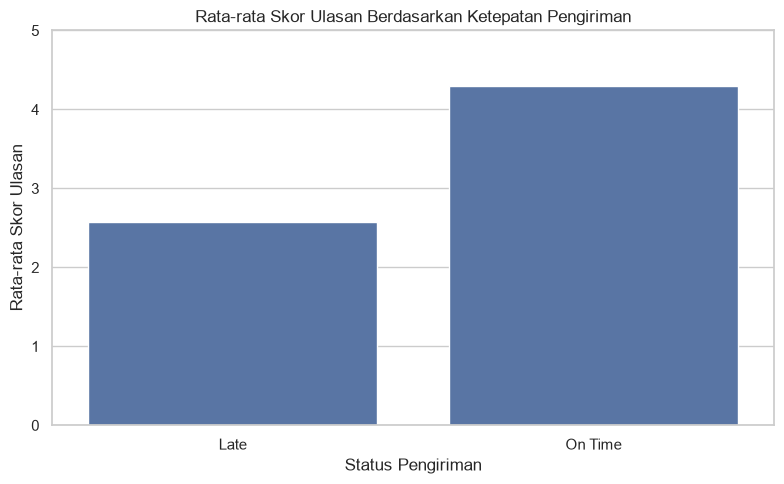

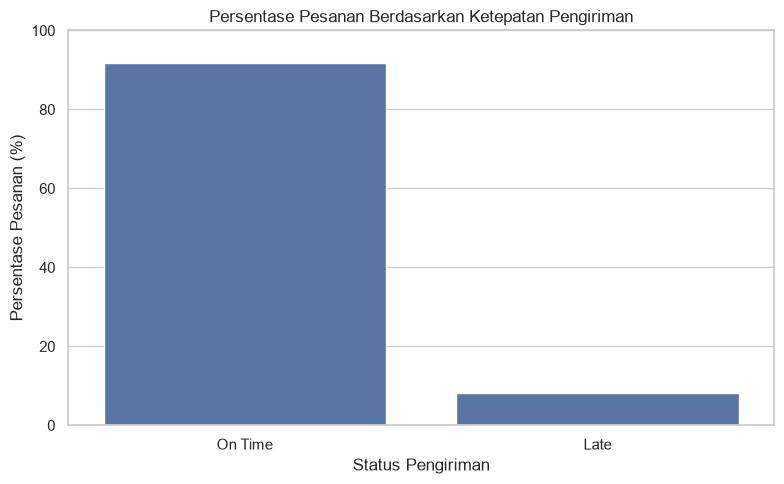

In [23]:
# Menyiapkan data untuk visualisasi
review_plot = review_summary.reset_index()

# Visualisasi rata-rata skor ulasan
plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_plot,
    x="delivery_status",
    y="rata_rata_review"
)

plt.title("Rata-rata Skor Ulasan Berdasarkan Ketepatan Pengiriman")
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-rata Skor Ulasan")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


# Visualisasi persentase ketepatan pengiriman
delivery_plot = delivery_summary.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_plot,
    x="delivery_status",
    y="Persentase (%)"
)

plt.title("Persentase Pesanan Berdasarkan Ketepatan Pengiriman")
plt.xlabel("Status Pengiriman")
plt.ylabel("Persentase Pesanan (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

**Insight:**
- Sebanyak 91,87% pesanan berhasil diterima tepat waktu.
- Sebanyak 8,13% pesanan mengalami keterlambatan.
- Pesanan yang diterima tepat waktu memperoleh rata-rata skor ulasan 4,30.
- Pesanan yang terlambat memperoleh rata-rata skor ulasan 2,57.
- Terdapat perbedaan rata-rata skor ulasan sebesar 1,73 poin antara pesanan tepat waktu dan terlambat.

## Analisis Lanjutan RFM

In [24]:
# Menentukan periode dan tanggal acuan analisis
snapshot_date = pd.Timestamp("2018-09-01")
start_date = pd.Timestamp("2017-01-01")

# Mengambil pesanan delivered pada periode analisis
rfm_orders = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_purchase_timestamp"] >= start_date) &
    (orders_clean["order_purchase_timestamp"] < snapshot_date)
].copy()

# Menggabungkan pesanan dengan identitas pelanggan unik
rfm_orders = rfm_orders.merge(
    customers_df[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Menghitung total harga produk untuk setiap pesanan
order_revenue = (
    order_items_clean
    .groupby("order_id")
    .agg(
        order_monetary=("price", "sum")
    )
    .reset_index()
)

# Menggabungkan total harga produk ke data pesanan
rfm_orders = rfm_orders.merge(
    order_revenue,
    on="order_id",
    how="inner"
)

# Memeriksa hasil penggabungan
print("Jumlah pesanan:", rfm_orders["order_id"].nunique())
print("Jumlah pelanggan unik:", rfm_orders["customer_unique_id"].nunique())
print("Total revenue:", rfm_orders["order_monetary"].sum())

display(rfm_orders.head())

Jumlah pesanan: 96211
Jumlah pelanggan unik: 93104
Total revenue: 13181027.13


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_monetary
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [25]:
# Menghitung nilai RFM untuk setiap pelanggan
rfm_df = (
    rfm_orders
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_monetary", "sum")
    )
    .reset_index()
)

# Menghitung Recency dalam satuan hari
rfm_df["recency"] = (
    snapshot_date - rfm_df["last_purchase"]
).dt.days

# Menyusun kolom RFM
rfm_df = rfm_df[
    ["customer_unique_id", "recency", "frequency", "monetary"]
]

# Menampilkan beberapa data pelanggan
display(rfm_df.head(10))

# Melihat statistik deskriptif RFM
display(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,113,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,18.90
2,0000f46a3911fa3c0805444483337064,539,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,323,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,290,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,148,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,133,1,27.99
7,00053a61a98854899e70ed204dd4bafe,184,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,545,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,172,1,104.90


,recency,frequency,monetary
count,"93,104.00","93,104.00","93,104.00"
mean,238.24,1.03,141.57
std,150.95,0.21,215.76
min,2.00,1.00,0.85
25%,116.00,1.00,47.65
50%,220.00,1.00,89.70
75%,347.00,1.00,154.17
max,603.00,15.00,"13,440.00"


**Insight:**
- Recency: Rata-rata pelanggan terakhir bertransaksi sekitar 238 hari sebelum 1 September 2018.
- Frequency: Rata-rata Frequency sebesar 1,03 transaksi. Bahkan, nilai median dan kuartil ketiga sama-sama 1 transaksi.
- Monetary: Rata-rata nilai pembelian pelanggan sebesar 141,57, sedangkan median sebesar 89,70.
- Nilai Monetary maksimum mencapai 13.440,00, jauh di atas median. Ini mengindikasikan distribusi pengeluaran yang kemungkinan menceng ke kanan (right-skewed).
- Frequency maksimum mencapai 15 transaksi, tetapi sebagian besar pelanggan hanya memiliki satu transaksi dalam periode pengamatan.

In [26]:
# Menghitung distribusi Frequency pelanggan
frequency_distribution = (
    rfm_df["frequency"]
    .value_counts()
    .sort_index()
    .to_frame("Jumlah Pelanggan")
)

frequency_distribution["Persentase (%)"] = (
    frequency_distribution["Jumlah Pelanggan"] /
    len(rfm_df) * 100
).round(2)

display(frequency_distribution)

# Menghitung jumlah pelanggan dengan pembelian berulang
repeat_customers = (rfm_df["frequency"] > 1).sum()
one_time_customers = (rfm_df["frequency"] == 1).sum()

print("Pelanggan dengan 1 transaksi:", one_time_customers)
print("Pelanggan dengan pembelian berulang:", repeat_customers)
print(
    "Persentase pelanggan berulang:",
    round(repeat_customers / len(rfm_df) * 100, 2),
    "%"
)

,Jumlah Pelanggan,Persentase (%)
frequency,,
1,90315,97.00
2,2562,2.75
3,180,0.19
4,28,0.03
5,9,0.01
6,5,0.01
7,3,0.00
9,1,0.00
15,1,0.00


Pelanggan dengan 1 transaksi: 90315
Pelanggan dengan pembelian berulang: 2789
Persentase pelanggan berulang: 3.0 %


**Insight:**
- Sebanyak 90.315 pelanggan (97%) hanya melakukan satu transaksi.
- Sebanyak 2.789 pelanggan (3%) melakukan pembelian berulang.
- Hanya 180 pelanggan yang melakukan tiga transaksi.
- Terdapat pelanggan dengan frekuensi pembelian hingga 15 transaksi, tetapi jumlahnya sangat sedikit.

In [27]:
# Membuat skor Recency dan Monetary berdasarkan kuantil
rfm_df["R_score"] = pd.qcut(
    rfm_df["recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm_df["M_score"] = pd.qcut(
    rfm_df["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Membuat skor Frequency berdasarkan jumlah transaksi
def frequency_score(value):
    if value == 1:
        return 1
    elif value == 2:
        return 2
    elif value == 3:
        return 3
    elif value <= 5:
        return 4
    else:
        return 5

rfm_df["F_score"] = rfm_df["frequency"].apply(frequency_score)

# Membuat skor gabungan RFM
rfm_df["RFM_score"] = (
    rfm_df["R_score"].astype(str) +
    rfm_df["F_score"].astype(str) +
    rfm_df["M_score"].astype(str)
)

# Menampilkan hasil scoring
display(
    rfm_df[
        [
            "customer_unique_id",
            "recency",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score"
        ]
    ].head(10)
)

# Memeriksa distribusi skor
display(
    rfm_df[["R_score", "F_score", "M_score"]]
    .describe()
    .round(2)
)

,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,113,1,129.90,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,116,1,18.90,4,1,1,411
2,0000f46a3911fa3c0805444483337064,539,1,69.00,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,323,1,25.99,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,290,1,180.00,2,1,5,215
5,0004bd2a26a76fe21f786e4fbd80607f,148,1,154.00,4,1,4,414
6,00050ab1314c0e55a6ca13cf7181fecf,133,1,27.99,4,1,1,411
7,00053a61a98854899e70ed204dd4bafe,184,1,382.00,3,1,5,315
8,0005e1862207bf6ccc02e4228effd9a0,545,1,135.00,1,1,4,114
9,0005ef4cd20d2893f0d9fbd94d3c0d97,172,1,104.90,4,1,3,413


,R_score,F_score,M_score
count,"93,104.00","93,104.00","93,104.00"
mean,3.00,1.03,3.00
std,1.41,0.20,1.41
min,1.00,1.00,1.00
25%,2.00,1.00,2.00
50%,3.00,1.00,3.00
75%,4.00,1.00,4.00
max,5.00,5.00,5.00


**Insight:**
- Recency: Skor rata-rata 3,00. Pelanggan terbagi relatif merata ke dalam lima kelompok berdasarkan kebaruan transaksi.
- Frequency: Skor rata-rata 1,03. Mayoritas pelanggan memperoleh skor 1 karena hanya melakukan satu transaksi.
- Monetary: Skor rata-rata 3,00. Pelanggan terbagi relatif merata berdasarkan nilai pembelian.
- Skor tertinggi pada masing-masing metrik adalah 5.

In [28]:
# Membuat fungsi segmentasi pelanggan
def segment_customer(row):
    if (
        row["R_score"] >= 4
        and row["F_score"] >= 3
        and row["M_score"] >= 3
    ):
        return "Best Customers"

    elif (
        row["F_score"] >= 2
        and row["R_score"] >= 3
    ):
        return "Loyal Customers"

    elif (
        row["R_score"] >= 4
        and row["F_score"] == 1
        and row["M_score"] >= 3
    ):
        return "Potential Customers"

    elif (
        row["R_score"] <= 2
        and row["F_score"] >= 2
    ):
        return "At Risk Customers"

    else:
        return "Others"


# Menerapkan segmentasi pada setiap pelanggan
rfm_df["customer_segment"] = rfm_df.apply(
    segment_customer,
    axis=1
)

# Menghitung jumlah pelanggan setiap segmen
segment_summary = (
    rfm_df
    .groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        total_revenue=("monetary", "sum"),
        average_monetary=("monetary", "mean")
    )
    .sort_values("total_customers", ascending=False)
)

# Menghitung persentase pelanggan
segment_summary["customer_percentage"] = (
    segment_summary["total_customers"] /
    segment_summary["total_customers"].sum() * 100
).round(2)

display(segment_summary.round(2))

,total_customers,total_revenue,average_monetary,customer_percentage
customer_segment,,,,
Others,68717,"7,967,087.65",115.94,73.81
Potential Customers,21598,"4,488,584.44",207.82,23.20
Loyal Customers,1679,"422,003.23",251.34,1.80
At Risk Customers,991,"247,228.56",249.47,1.06
Best Customers,119,"56,123.25",471.62,0.13


Basis pelanggan dalam periode pengamatan didominasi pembeli satu kali

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
  Berdasarkan analisis penjualan periode Januari 2017 hingga Agustus 2018, kategori produk dengan total revenue tertinggi adalah **health_beauty**, dengan nilai penjualan sebesar **R$ 1.229.557,50**. Posisi berikutnya ditempati kategori **watches_gifts** sebesar **R$ 1.163.465,91**, dan **bed_bath_table** sebesar **R$ 1.022.955,77**. Sementara itu, kategori bed_bath_table memiliki jumlah item terjual terbanyak, yaitu 10.945 item. Hal ini menunjukkan bahwa kategori dengan jumlah item terjual tertinggi belum tentu menjadi kategori dengan revenue tertinggi. Perusahaan dapat memprioritaskan kategori health_beauty dan watches_gifts dalam strategi penjualan karena keduanya memberikan kontribusi revenue terbesar.

- **Conclusion pertanyaan 2:**
  Dari pesanan yang berhasil dikirim dan memiliki informasi tanggal pengiriman yang valid, sebanyak **91,87%** pesanan diterima tepat waktu, sedangkan **8,13%** mengalami keterlambatan. Analisis skor ulasan menunjukkan bahwa pesanan yang diterima tepat waktu memiliki rata-rata skor ulasan **4,30**, sedangkan pesanan terlambat memiliki rata-rata skor **2,57**. Terdapat selisih sebesar **1,73 poin** antara kedua kelompok tersebut. Hasil ini menunjukkan adanya hubungan antara ketepatan waktu pengiriman dan skor ulasan pelanggan. Namun, hasil analisis ini tidak membuktikan bahwa keterlambatan pengiriman merupakan satu-satunya penyebab rendahnya skor ulasan.

- **Conclusion analisis lanjutan (RFM):**
  Analisis RFM terhadap **93.104 pelanggan** menunjukkan bahwa mayoritas pelanggan melakukan pembelian satu kali selama periode pengamatan. Sebanyak **90.315 pelanggan (97%)** hanya melakukan satu transaksi, sedangkan **2.789 pelanggan (3%)** melakukan pembelian berulang. Berdasarkan segmentasi RFM, kelompok Others merupakan segmen terbesar dengan 68.717 pelanggan (73,81%), diikuti Potential Customers sebanyak 21.598 pelanggan (23,20%). Walaupun Best Customers hanya terdiri dari 119 pelanggan (0,13%), kelompok ini memiliki rata-rata Monetary tertinggi, yaitu **R$ 471,62**. Temuan ini menunjukkan adanya peluang untuk meningkatkan pembelian berulang serta mempertahankan pelanggan dengan nilai transaksi tinggi. Perlu diperhatikan bahwa hasil RFM hanya menggambarkan perilaku pembelian selama Januari 2017 hingga Agustus 2018.



**Rekomendasi Action Item:**
- **Mempertahankan dan mengembangkan kategori dengan revenue tinggi:** Memprioritaskan kategori health_beauty dan watches_gifts melalui pengelolaan stok, promosi yang relevan, serta evaluasi performa penjualan secara berkala. Kategori bed_bath_table juga perlu diperhatikan karena memiliki jumlah item terjual tertinggi.

- **Meningkatkan ketepatan waktu pengiriman:** Melakukan evaluasi terhadap proses pemenuhan pesanan, kinerja penjual, dan mitra logistik, terutama pada pesanan yang berisiko terlambat. Perusahaan dapat memantau persentase keterlambatan secara berkala dan menetapkan target penurunan tingkat keterlambatan.

- **Meningkatkan pembelian berulang:** Menjalankan program retensi pelanggan seperti voucher pembelian berikutnya, rekomendasi produk berdasarkan riwayat pembelian, dan promosi yang dipersonalisasi untuk pelanggan yang baru melakukan satu transaksi.

- **Mempertahankan pelanggan bernilai tinggi:** Memberikan program loyalitas atau penawaran eksklusif kepada pelanggan dengan skor RFM tinggi agar mereka tetap aktif dan melakukan transaksi kembali.

- **Melakukan evaluasi segmentasi pelanggan secara berkala:** Memperbarui perhitungan RFM secara periodik agar perubahan perilaku pelanggan dapat terpantau dan strategi pemasaran dapat disesuaikan dengan kondisi terbaru.